# Laptop Price Prediction — End-to-End Regression Case Study

**Dataset:** `data.csv` (Laptop Specifications & Pricing)  
**Task:** Supervised Regression (Predicting `price` in INR)  

### 15-Step Workflow
1. **Load** — Import libraries and load `data.csv`  
2. **Inspect** — Check shape, data types, missing values, duplicates, and distributions  
3. **Clean** — Remove index columns, standardize RAM/OS categories, strip whitespace  
4. **Feature Engineering** — Extract numeric RAM/ROM, CPU brand & cores, GPU brand/VRAM, PPI, and Gaming flag  
5. **EDA** — Visualize price distribution, brand pricing, hardware impact, and correlations  
6. **Define Target / Labels** — Set continuous target `y = price` and feature matrix `X`  
7. **Split** — 80/20 Train-Test split  
8. **Preprocess** — Build leakage-free `ColumnTransformer` pipeline  
9. **Train** — Train 4 regression models (Ridge, Decision Tree, Random Forest, Gradient Boosting)  
10. **Predict** — Generate price predictions on the held-out test set  
11. **Evaluate** — Compare $R^2$, RMSE, MAE, MAPE, Actual vs Predicted, and Residuals  
12. **Interpret** — Built-in Feature Importances & Permutation Importance  
13. **Validate** — 5-Fold Cross-Validation & Overfitting Check  
14. **Save Artifacts** — Persist best pipeline (`joblib`), metadata (`json`), and test predictions (`csv`)  
15. **Demo Prediction** — Reload saved model and predict prices for new laptop configurations

## Step 1: Load
Import required libraries and load `data.csv`.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import re
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
from sklearn.inspection import permutation_importance

sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams['figure.dpi'] = 100

DATA_PATH = 'data.csv'
df_raw = pd.read_csv(DATA_PATH)

print(f"Dataset loaded successfully! Shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
df_raw.head()

Dataset loaded successfully! Shape: 893 rows x 18 columns


,Unnamed: 0.1,Unnamed: 0,brand,name,price,spec_rating,processor,CPU,Ram,Ram_type,ROM,ROM_type,GPU,display_size,resolution_width,resolution_height,OS,warranty
0,0,0,HP,Victus 15-fb0157AX Gaming Laptop,49900,73.000000,5th Gen AMD Ryzen 5 5600H,"Hexa Core, 12 Threads",8GB,DDR4,512GB,SSD,4GB AMD Radeon RX 6500M,15.6,1920.0,1080.0,Windows 11 OS,1
1,1,1,HP,15s-fq5007TU Laptop,39900,60.000000,12th Gen Intel Core i3 1215U,"Hexa Core (2P + 4E), 8 Threads",8GB,DDR4,512GB,SSD,Intel UHD Graphics,15.6,1920.0,1080.0,Windows 11 OS,1
2,2,2,Acer,One 14 Z8-415 Laptop,26990,69.323529,11th Gen Intel Core i3 1115G4,"Dual Core, 4 Threads",8GB,DDR4,512GB,SSD,Intel Iris Xe Graphics,14.0,1920.0,1080.0,Windows 11 OS,1
3,3,3,Lenovo,Yoga Slim 6 14IAP8 82WU0095IN Laptop,59729,66.000000,12th Gen Intel Core i5 1240P,"12 Cores (4P + 8E), 16 Threads",16GB,LPDDR5,512GB,SSD,Intel Integrated Iris Xe,14.0,2240.0,1400.0,Windows 11 OS,1
4,4,4,Apple,MacBook Air 2020 MGND3HN Laptop,69990,69.323529,Apple M1,Octa Core (4P + 4E),8GB,DDR4,256GB,SSD,Apple M1 Integrated Graphics,13.3,2560.0,1600.0,Mac OS,1


## Step 2: Inspect
Check column names, data types, missing values, duplicates, target summary statistics, and categorical cardinality.

In [2]:
print("1. Columns:")
print(df_raw.columns.tolist())

print("\n2. Data Types:")
print(df_raw.dtypes)

print("\n3. Missing Values:")
print(df_raw.isnull().sum()[df_raw.isnull().sum() > 0] if df_raw.isnull().sum().sum() > 0 else "   No missing values found!")

print(f"\n4. Duplicate Rows: {df_raw.duplicated().sum()}")

print("\n5. Target Variable (`price`) Summary:")
print(df_raw['price'].describe().round(2))

print("\n6. Unique Values per Categorical Column:")
for col in df_raw.select_dtypes(include='object').columns:
    print(f"   {col:12s}: {df_raw[col].nunique()} unique values")

1. Columns:
['Unnamed: 0.1', 'Unnamed: 0', 'brand', 'name', 'price', 'spec_rating', 'processor', 'CPU', 'Ram', 'Ram_type', 'ROM', 'ROM_type', 'GPU', 'display_size', 'resolution_width', 'resolution_height', 'OS', 'warranty']

2. Data Types:
Unnamed: 0.1           int64
Unnamed: 0             int64
brand                 object
name                  object
price                  int64
spec_rating          float64
processor             object
CPU                   object
Ram                   object
Ram_type              object
ROM                   object
ROM_type              object
GPU                   object
display_size         float64
resolution_width     float64
resolution_height    float64
OS                    object
warranty               int64
dtype: object

3. Missing Values:
   No missing values found!

4. Duplicate Rows: 0

5. Target Variable (`price`) Summary:
count       893.00
mean      79907.41
std       60880.04
min        9999.00
25%       44500.00
50%       61990.00
7

## Step 3: Clean
Based on our inspection, we clean the dataset by:
1. Dropping redundant CSV index columns (`Unnamed: 0.1`, `Unnamed: 0`).
2. Stripping extra whitespace/tabs from all string columns.
3. Standardizing inconsistent `Ram_type` labels (`LPDDR4x` -> `LPDDR4X`, `LPDDR5x` -> `LPDDR5X`, `DDR4-` -> `DDR4`).
4. Grouping messy `OS` strings into clean categories (`Windows 11`, `Windows 10`, `Mac OS`, `DOS`, `Chrome OS`, `Other`).

In [3]:
def clean_raw_data(data: pd.DataFrame) -> pd.DataFrame:
    d = data.copy()
    # 1. Drop redundant index columns if present
    drop_idx = [c for c in ['Unnamed: 0.1', 'Unnamed: 0'] if c in d.columns]
    if drop_idx:
        d = d.drop(columns=drop_idx)

    # 2. Strip whitespace and tabs from string columns
    for col in d.select_dtypes(include='object').columns:
        d[col] = d[col].astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()

    # 3. Standardize Ram_type
    ram_type_map = {
        'LPDDR4x': 'LPDDR4X',
        'LPDDR5x': 'LPDDR5X',
        'DDR4-': 'DDR4',
        'DDR': 'DDR4'
    }
    d['Ram_type'] = d['Ram_type'].replace(ram_type_map)

    # 4. Standardize OS into clean categories
    def simplify_os(val):
        v = str(val).lower()
        if 'windows 11' in v:
            return 'Windows 11'
        elif 'windows 10' in v:
            return 'Windows 10'
        elif 'windows' in v:
            return 'Windows Other'
        elif 'mac' in v:
            return 'Mac OS'
        elif 'dos' in v:
            return 'DOS'
        elif 'chrome' in v:
            return 'Chrome OS'
        else:
            return 'Other'

    d['OS'] = d['OS'].apply(simplify_os)
    return d

df_clean = clean_raw_data(df_raw)

print(f"Cleaned shape: {df_clean.shape}")
print("\nStandardized OS counts:")
print(df_clean['OS'].value_counts())
print("\nStandardized Ram_type counts:")
print(df_clean['Ram_type'].value_counts())

Cleaned shape: (893, 16)

Standardized OS counts:
OS
Windows 11       797
Windows 10        38
DOS               20
Mac OS            16
Chrome OS         10
Windows Other      9
Other              3
Name: count, dtype: int64

Standardized Ram_type counts:
Ram_type
DDR4       501
DDR5       166
LPDDR5     145
LPDDR4X     54
LPDDR4      14
Unified      7
LPDDR5X      3
DDR3         3
Name: count, dtype: int64


## Step 4: Feature Engineering
Extract structured numeric and categorical hardware features from raw text fields:
- **`ram_gb`**: Numeric RAM in GB (e.g., `16GB` -> `16`).
- **`rom_gb`**: Numeric storage in GB (e.g., `1TB` -> `1024`, `512GB` -> `512`).
- **`cpu_brand`**: `Intel`, `AMD`, `Apple`, or `Other`.
- **`cpu_tier`**: Processor tier (`i3/Ryzen 3`, `i5/Ryzen 5`, `i7/Ryzen 7`, `i9/Ryzen 9`, `Apple M`, `Budget/Other`).
- **`cpu_cores`**: Parsed physical core count from `CPU`.
- **`gpu_brand`**: `NVIDIA`, `AMD`, `Intel`, `Apple`, or `Other`.
- **`has_dedicated_gpu`**: `1` if discrete GPU (NVIDIA / VRAM specified), else `0`.
- **`gpu_vram_gb`**: Extracted dedicated GPU VRAM in GB (`0` for integrated).
- **`ppi`**: Display Pixels Per Inch ($\sqrt{W^2 + H^2} / \text{display\_size}$).
- **`is_gaming`**: `1` if laptop name indicates a gaming model, else `0`.
- **`brand_grouped`**: Top 9 brands kept, rare brands grouped as `Other`.

In [4]:
TOP_BRANDS = ['HP', 'Lenovo', 'Asus', 'Dell', 'Acer', 'MSI', 'Samsung', 'Apple', 'Infinix']

def parse_storage_gb(val):
    s = str(val).upper().strip()
    m = re.search(r'(\d+)', s)
    if not m:
        return np.nan
    num = int(m.group(1))
    return num * 1024 if 'TB' in s else num

def parse_cpu_cores(val):
    s = str(val).lower()
    word_map = {'dual': 2, 'quad': 4, 'hexa': 6, 'octa': 8}
    for k, v in word_map.items():
        if k in s:
            return v
    m = re.search(r'(\d+)\s*cores?', s)
    return int(m.group(1)) if m else 4

def parse_cpu_brand(val):
    s = str(val).lower()
    if 'intel' in s:
        return 'Intel'
    elif 'amd' in s or 'ryzen' in s:
        return 'AMD'
    elif 'apple' in s:
        return 'Apple'
    return 'Other'

def parse_cpu_tier(val):
    s = str(val).lower()
    if 'i9' in s or 'ryzen 9' in s:
        return 'Tier_9'
    elif 'i7' in s or 'ryzen 7' in s:
        return 'Tier_7'
    elif 'i5' in s or 'ryzen 5' in s:
        return 'Tier_5'
    elif 'i3' in s or 'ryzen 3' in s:
        return 'Tier_3'
    elif 'apple' in s or 'm1' in s or 'm2' in s or 'm3' in s:
        return 'Apple_M'
    return 'Entry_Other'

def parse_gpu_brand(val):
    s = str(val).lower()
    if 'nvidia' in s or 'geforce' in s or 'rtx' in s or 'gtx' in s:
        return 'NVIDIA'
    elif 'amd' in s or 'radeon' in s:
        return 'AMD'
    elif 'intel' in s:
        return 'Intel'
    elif 'apple' in s:
        return 'Apple'
    return 'Other'

def parse_gpu_vram(val):
    s = str(val).upper()
    m = re.search(r'(\d+)\s*GB', s)
    return int(m.group(1)) if m else 0

def add_engineered_features(data: pd.DataFrame) -> pd.DataFrame:
    d = data.copy()
    d['ram_gb'] = d['Ram'].apply(parse_storage_gb)
    d['rom_gb'] = d['ROM'].apply(parse_storage_gb)
    d['cpu_brand'] = d['processor'].apply(parse_cpu_brand)
    d['cpu_tier'] = d['processor'].apply(parse_cpu_tier)
    d['cpu_cores'] = d['CPU'].apply(parse_cpu_cores)
    d['gpu_brand'] = d['GPU'].apply(parse_gpu_brand)
    d['gpu_vram_gb'] = d['GPU'].apply(parse_gpu_vram)
    d['has_dedicated_gpu'] = ((d['gpu_vram_gb'] > 0) | (d['gpu_brand'] == 'NVIDIA')).astype(int)
    d['ppi'] = np.sqrt(d['resolution_width']**2 + d['resolution_height']**2) / d['display_size']
    d['is_gaming'] = d['name'].str.lower().str.contains(
        'gaming|rog|tuf|victus|omen|legion|nitro|predator|alienware|katana|strix|zephyrus|loq|ideapad gaming',
        regex=True
    ).astype(int)
    d['brand_grouped'] = d['brand'].where(d['brand'].isin(TOP_BRANDS), 'Other')

    # Drop raw text columns replaced by engineered features
    drop_raw = ['brand', 'name', 'processor', 'CPU', 'Ram', 'ROM', 'GPU']
    d = d.drop(columns=[c for c in drop_raw if c in d.columns])
    return d

df = add_engineered_features(df_clean)

print("Feature engineering complete! New shape:", df.shape)
print("Final columns:", df.columns.tolist())
df[['spec_rating', 'ram_gb', 'rom_gb', 'cpu_cores', 'gpu_vram_gb', 'ppi', 'is_gaming', 'price']].head()

Feature engineering complete! New shape: (893, 20)
Final columns: ['price', 'spec_rating', 'Ram_type', 'ROM_type', 'display_size', 'resolution_width', 'resolution_height', 'OS', 'warranty', 'ram_gb', 'rom_gb', 'cpu_brand', 'cpu_tier', 'cpu_cores', 'gpu_brand', 'gpu_vram_gb', 'has_dedicated_gpu', 'ppi', 'is_gaming', 'brand_grouped']


,spec_rating,ram_gb,rom_gb,cpu_cores,gpu_vram_gb,ppi,is_gaming,price
0,73.000000,8,512,6,4,141.211998,1,49900
1,60.000000,8,512,6,0,141.211998,0,39900
2,69.323529,8,512,2,0,157.350512,0,26990
3,66.000000,16,512,12,0,188.679623,0,59729
4,69.323529,8,256,8,0,226.983005,0,69990


## Step 5: EDA (Exploratory Data Analysis)
Explore the target `price` distribution, pricing across brands and RAM sizes, and feature correlations.

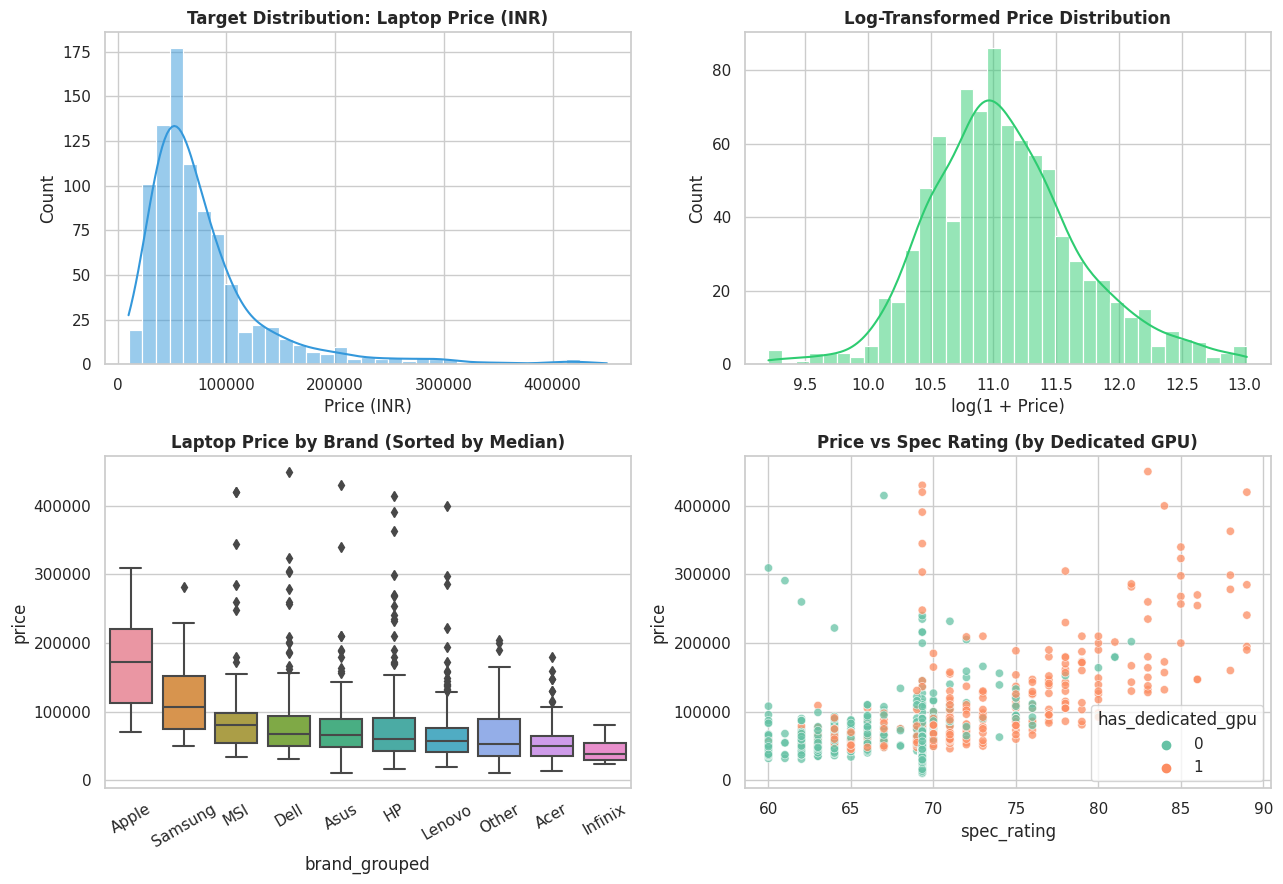

In [5]:
# 5.1 Price distribution & key feature relationships
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Price histogram
sns.histplot(df['price'], kde=True, bins=35, color='#3498db', ax=axes[0, 0])
axes[0, 0].set_title('Target Distribution: Laptop Price (INR)', fontweight='bold')
axes[0, 0].set_xlabel('Price (INR)')

# Log-Price histogram
sns.histplot(np.log1p(df['price']), kde=True, bins=35, color='#2ecc71', ax=axes[0, 1])
axes[0, 1].set_title('Log-Transformed Price Distribution', fontweight='bold')
axes[0, 1].set_xlabel('log(1 + Price)')

# Price by Brand
brand_order = df.groupby('brand_grouped')['price'].median().sort_values(ascending=False).index
sns.boxplot(data=df, x='brand_grouped', y='price', order=brand_order, ax=axes[1, 0])
axes[1, 0].set_title('Laptop Price by Brand (Sorted by Median)', fontweight='bold')
axes[1, 0].tick_params(axis='x', rotation=30)

# Price vs Spec Rating colored by Dedicated GPU
sns.scatterplot(data=df, x='spec_rating', y='price', hue='has_dedicated_gpu', alpha=0.75, ax=axes[1, 1])
axes[1, 1].set_title('Price vs Spec Rating (by Dedicated GPU)', fontweight='bold')

plt.tight_layout()
plt.show()

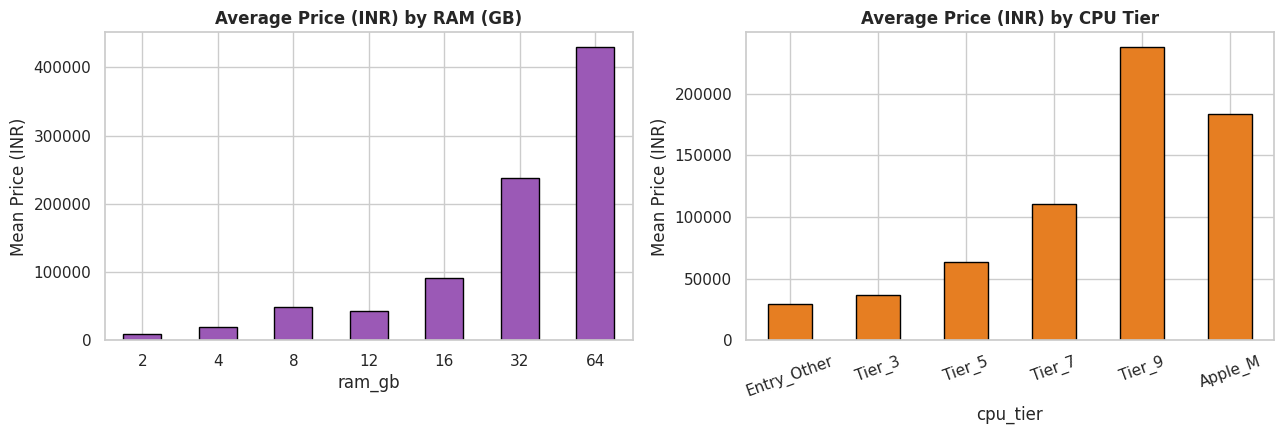

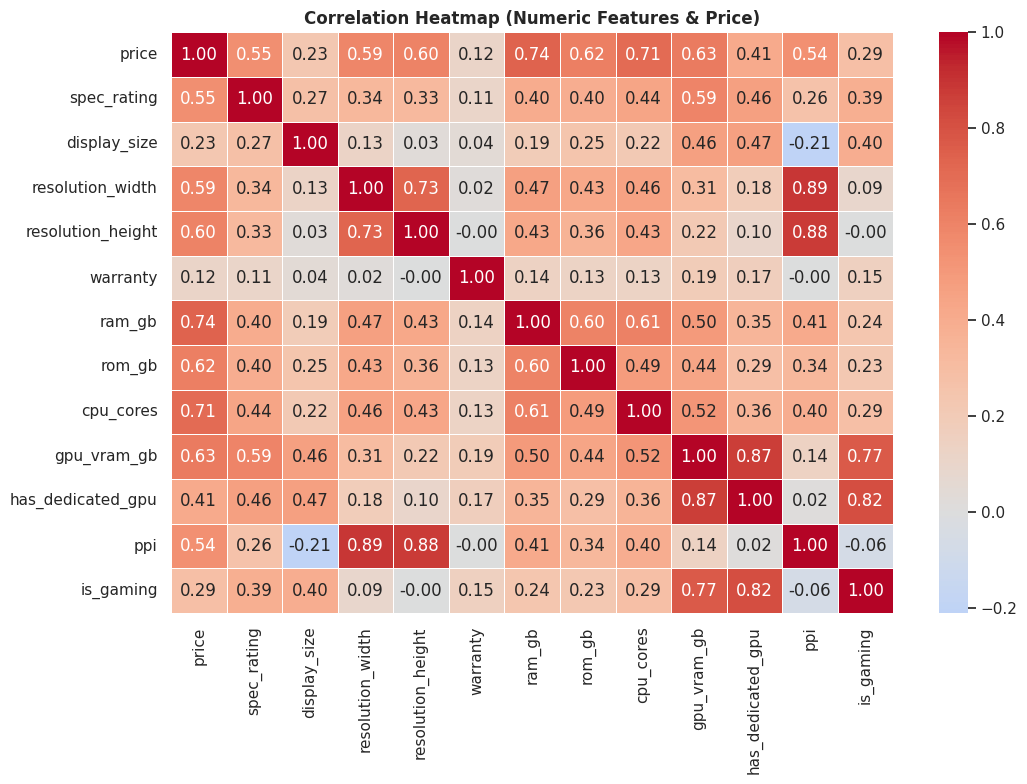

In [6]:
# 5.2 Average Price by RAM & CPU Tier + Numeric Correlation Heatmap
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ram_price = df.groupby('ram_gb')['price'].mean()
ram_price.plot(kind='bar', color='#9b59b6', edgecolor='black', ax=axes[0])
axes[0].set_title('Average Price (INR) by RAM (GB)', fontweight='bold')
axes[0].set_ylabel('Mean Price (INR)')
axes[0].tick_params(axis='x', rotation=0)

tier_order = ['Entry_Other', 'Tier_3', 'Tier_5', 'Tier_7', 'Tier_9', 'Apple_M']
tier_price = df.groupby('cpu_tier')['price'].mean().reindex(tier_order)
tier_price.plot(kind='bar', color='#e67e22', edgecolor='black', ax=axes[1])
axes[1].set_title('Average Price (INR) by CPU Tier', fontweight='bold')
axes[1].set_ylabel('Mean Price (INR)')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

# Correlation Heatmap
num_cols_eda = df.select_dtypes(include='number').columns
plt.figure(figsize=(11, 8))
sns.heatmap(df[num_cols_eda].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Correlation Heatmap (Numeric Features & Price)', fontweight='bold')
plt.tight_layout()
plt.show()

## Step 6: Define Target / Labels
Define continuous regression target `y = price` and separate feature matrix `X` into numeric and categorical columns.

In [7]:
TARGET_COL = 'price'
y = df[TARGET_COL].copy()
X = df.drop(columns=[TARGET_COL])

numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"Target: {TARGET_COL} | Mean: ₹{y.mean():,.0f} | Median: ₹{y.median():,.0f} | Range: ₹{y.min():,.0f} – ₹{y.max():,.0f}")
print(f"Total features: {X.shape[1]}")
print(f"Numeric features ({len(numeric_features)}): {numeric_features}")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")

Target: price | Mean: ₹79,907 | Median: ₹61,990 | Range: ₹9,999 – ₹450,039
Total features: 19
Numeric features (12): ['spec_rating', 'display_size', 'resolution_width', 'resolution_height', 'warranty', 'ram_gb', 'rom_gb', 'cpu_cores', 'gpu_vram_gb', 'has_dedicated_gpu', 'ppi', 'is_gaming']
Categorical features (7): ['Ram_type', 'ROM_type', 'OS', 'cpu_brand', 'cpu_tier', 'gpu_brand', 'brand_grouped']


## Step 7: Split
Perform an 80/20 Train-Test split (`random_state=42`).

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Training set: {X_train.shape[0]:,} rows ({X_train.shape[0]/len(X)*100:.1f}%) | Mean Price: ₹{y_train.mean():,.0f}")
print(f"Test set:     {X_test.shape[0]:,} rows ({X_test.shape[0]/len(X)*100:.1f}%) | Mean Price: ₹{y_test.mean():,.0f}")

Training set: 714 rows (80.0%) | Mean Price: ₹80,520
Test set:     179 rows (20.0%) | Mean Price: ₹77,465


## Step 8: Preprocess
Build a leakage-free `ColumnTransformer` to impute and scale numeric features and one-hot encode categorical features.

In [9]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

X_train_preview = preprocessor.fit_transform(X_train)
print(f"Preprocessed training matrix shape: {X_train_preview.shape}")
print(f"Total encoded features: {len(preprocessor.get_feature_names_out())}")

Preprocessed training matrix shape: (714, 47)
Total encoded features: 47


## Step 9: Train
Train four regression models inside full preprocessing pipelines:
1. **Ridge Regression** (regularized linear baseline)
2. **Decision Tree Regressor** (non-linear baseline)
3. **Random Forest Regressor** (bagging ensemble)
4. **Gradient Boosting Regressor** (boosting ensemble)

In [10]:
models = {
    'Ridge Regression': Ridge(alpha=10.0, random_state=42),
    'Decision Tree': DecisionTreeRegressor(max_depth=10, min_samples_leaf=4, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=300, max_depth=15, min_samples_leaf=2, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=250, learning_rate=0.05, max_depth=4, random_state=42)
}

trained_pipelines = {}
for name, reg in models.items():
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', reg)
    ])
    pipe.fit(X_train, y_train)
    trained_pipelines[name] = pipe
    print(f"Trained: {name}")

Trained: Ridge Regression
Trained: Decision Tree
Trained: Random Forest
Trained: Gradient Boosting


## Step 10: Predict
Generate predicted laptop prices on the held-out test set for all four models.

In [11]:
predictions = {}
for name, pipe in trained_pipelines.items():
    predictions[name] = pipe.predict(X_test)

# Preview sample predictions from Gradient Boosting
sample_pred_df = pd.DataFrame({
    'Brand': X_test['brand_grouped'].values[:10],
    'RAM_GB': X_test['ram_gb'].values[:10],
    'CPU_Tier': X_test['cpu_tier'].values[:10],
    'Actual_Price': y_test.values[:10],
    'Predicted_GB': np.round(predictions['Gradient Boosting'][:10], 0).astype(int),
    'Abs_Error': np.round(np.abs(y_test.values[:10] - predictions['Gradient Boosting'][:10]), 0).astype(int)
})
print("Sample Test Predictions (First 10 rows):")
print(sample_pred_df.to_string(index=False))

Sample Test Predictions (First 10 rows):
 Brand  RAM_GB    CPU_Tier  Actual_Price  Predicted_GB  Abs_Error
  Dell      16      Tier_5         83090         94265      11175
    HP      16      Tier_5         57580         64581       7001
  Asus      16      Tier_5         58990         54094       4896
  Asus      16      Tier_7        142990        142759        231
Lenovo      16      Tier_5         74990         88443      13453
  Acer      16      Tier_5         56990         68110      11120
Lenovo       8      Tier_3         53990         43437      10553
    HP       8      Tier_5         57990         56420       1570
  Asus      16      Tier_5         72490         70479       2011
    HP       4 Entry_Other         23990         17789       6201


## Step 11: Evaluate
Compare all four models on **$R^2$**, **RMSE**, **MAE**, and **MAPE (%)**, and inspect Actual vs Predicted and Residual plots for the best model.

In [12]:
eval_rows = []
for name in trained_pipelines:
    y_pred = predictions[name]
    eval_rows.append({
        'Model': name,
        'R2_Score': r2_score(y_test, y_pred),
        'RMSE_INR': np.sqrt(mean_squared_error(y_test, y_pred)),
        'MAE_INR': mean_absolute_error(y_test, y_pred),
        'MAPE_%': mean_absolute_percentage_error(y_test, y_pred) * 100
    })

results_df = pd.DataFrame(eval_rows).sort_values(by='R2_Score', ascending=False).reset_index(drop=True)
print("Model Evaluation Comparison (Test Set):")
print(results_df.round(4).to_string(index=False))

best_model_name = results_df.loc[0, 'Model']
best_pipeline = trained_pipelines[best_model_name]
print(f"\nBest Performing Model: {best_model_name} (R2 = {results_df.loc[0, 'R2_Score']:.4f}, MAE = ₹{results_df.loc[0, 'MAE_INR']:,.0f})")

Model Evaluation Comparison (Test Set):
            Model  R2_Score   RMSE_INR    MAE_INR  MAPE_%
Gradient Boosting    0.8856 19799.0984 11115.4691 13.5625
 Ridge Regression    0.8786 20395.0467 14019.7819 20.2583
    Random Forest    0.8620 21745.8648 12390.3849 15.2881
    Decision Tree    0.7787 27538.8783 15248.7544 19.2418

Best Performing Model: Gradient Boosting (R2 = 0.8856, MAE = ₹11,115)


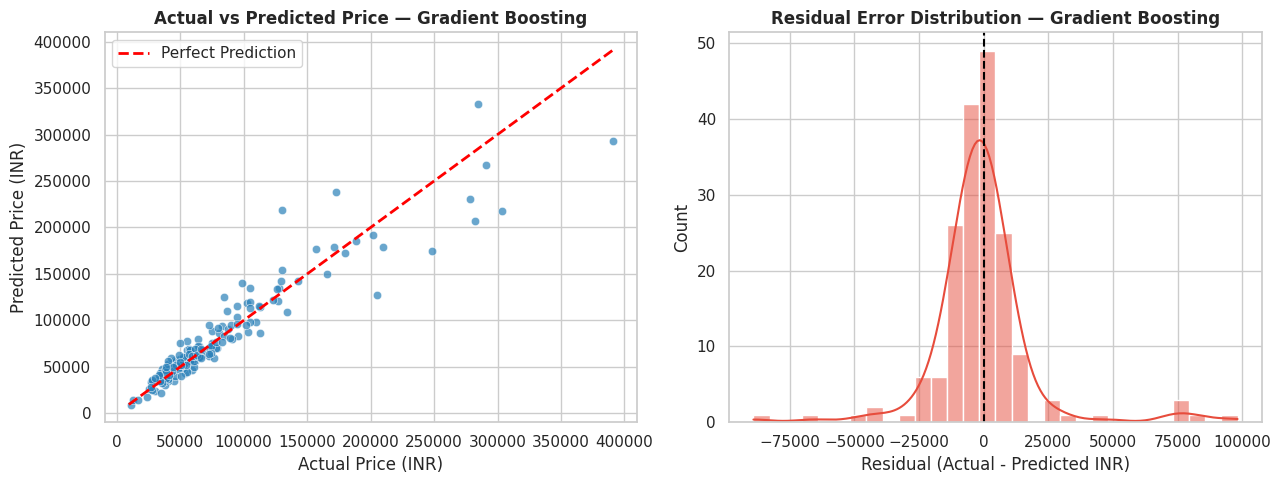

In [13]:
# Actual vs Predicted & Residuals Plot (Best Model)
best_preds = predictions[best_model_name]
residuals = y_test - best_preds

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Actual vs Predicted
sns.scatterplot(x=y_test, y=best_preds, alpha=0.7, color='#2980b9', ax=axes[0])
min_val = min(y_test.min(), best_preds.min())
max_val = max(y_test.max(), best_preds.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect Prediction')
axes[0].set_title(f'Actual vs Predicted Price — {best_model_name}', fontweight='bold')
axes[0].set_xlabel('Actual Price (INR)')
axes[0].set_ylabel('Predicted Price (INR)')
axes[0].legend()

# Residuals Distribution
sns.histplot(residuals, kde=True, bins=30, color='#e74c3c', ax=axes[1])
axes[1].axvline(0, color='black', linestyle='--', lw=1.5)
axes[1].set_title(f'Residual Error Distribution — {best_model_name}', fontweight='bold')
axes[1].set_xlabel('Residual (Actual - Predicted INR)')

plt.tight_layout()
plt.show()

## Step 12: Interpret
Identify the strongest price drivers using both **Built-in Feature Importances** and **Permutation Importance** on the test set.

Top 5 Most Influential Features (Permutation Importance):
          Feature  Perm_Importance_Mean  Perm_Importance_Std
      gpu_vram_gb                0.1204               0.0113
      spec_rating                0.0581               0.0072
              ppi                0.0555               0.0074
        cpu_cores                0.0495               0.0106
resolution_height                0.0411               0.0097


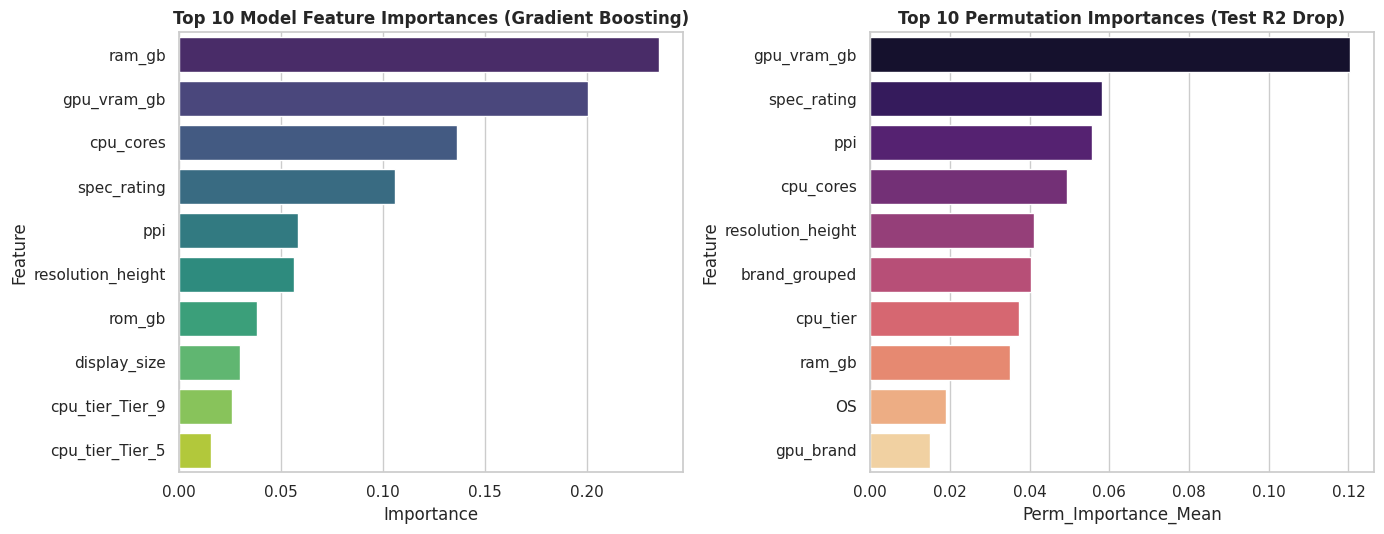

In [14]:
reg_step = best_pipeline.named_steps['regressor']
prep_step = best_pipeline.named_steps['preprocessor']
feat_names = [f.replace('num__', '').replace('cat__', '') for f in prep_step.get_feature_names_out()]

if hasattr(reg_step, 'feature_importances_'):
    importances = reg_step.feature_importances_
else:
    importances = np.abs(reg_step.coef_)

fi_df = pd.DataFrame({'Feature': feat_names, 'Importance': importances}).sort_values('Importance', ascending=False)

perm = permutation_importance(best_pipeline, X_test, y_test, n_repeats=10, random_state=42, scoring='r2')
perm_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Perm_Importance_Mean': perm.importances_mean,
    'Perm_Importance_Std': perm.importances_std
}).sort_values('Perm_Importance_Mean', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.barplot(data=fi_df.head(10), x='Importance', y='Feature', ax=axes[0], palette='viridis')
axes[0].set_title(f'Top 10 Model Feature Importances ({best_model_name})', fontweight='bold')

sns.barplot(data=perm_df.head(10), x='Perm_Importance_Mean', y='Feature', ax=axes[1], palette='magma')
axes[1].set_title('Top 10 Permutation Importances (Test R2 Drop)', fontweight='bold')

plt.tight_layout()
plt.show()

print("Top 5 Most Influential Features (Permutation Importance):")
print(perm_df.head(5).round(4).to_string(index=False))

## Step 13: Validate
Verify generalization and check for overfitting using **5-Fold Cross-Validation** across all models.

In [15]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'r2': 'r2', 'rmse': 'neg_root_mean_squared_error', 'mae': 'neg_mean_absolute_error'}

cv_rows = []
for name, reg in models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('regressor', reg)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, return_train_score=True, n_jobs=-1)
    cv_rows.append({
        'Model': name,
        'Train_R2': scores['train_r2'].mean(),
        'CV_R2_Mean': scores['test_r2'].mean(),
        'CV_R2_Std': scores['test_r2'].std(),
        'CV_RMSE_INR': -scores['test_rmse'].mean(),
        'CV_MAE_INR': -scores['test_mae'].mean(),
        'Overfit_Gap_R2': scores['train_r2'].mean() - scores['test_r2'].mean()
    })

cv_df = pd.DataFrame(cv_rows).sort_values('CV_R2_Mean', ascending=False).reset_index(drop=True)
print("5-Fold Cross-Validation Results:")
print(cv_df.round(4).to_string(index=False))

5-Fold Cross-Validation Results:
            Model  Train_R2  CV_R2_Mean  CV_R2_Std  CV_RMSE_INR  CV_MAE_INR  Overfit_Gap_R2
 Ridge Regression    0.8570      0.8206     0.0970   24947.5794  15304.8757          0.0364
    Random Forest    0.9471      0.8070     0.0888   26273.2083  13876.8346          0.1401
Gradient Boosting    0.9868      0.7925     0.1025   26847.6820  13607.6631          0.1942
    Decision Tree    0.8980      0.7055     0.0778   32837.8051  17751.7737          0.1925


## Step 14: Save Artifacts
Persist the best regression pipeline (`joblib`), model metadata (`json`), and test predictions (`csv`) for deployment.

In [16]:
MODEL_FILE = 'laptop_price_best_model.joblib'
META_FILE = 'regression_model_metadata.json'
PRED_FILE = 'regression_test_predictions.csv'

# 1. Save best trained pipeline
joblib.dump(best_pipeline, MODEL_FILE)

# 2. Save metadata
best_row = results_df.loc[0].to_dict()
metadata = {
    'task': 'regression',
    'target': TARGET_COL,
    'best_model_name': best_model_name,
    'model_features': X.columns.tolist(),
    'test_metrics': {k: round(float(v), 4) for k, v in best_row.items() if k != 'Model'}
}
with open(META_FILE, 'w') as f:
    json.dump(metadata, f, indent=2)

# 3. Save test predictions
out_preds = X_test.copy()
out_preds['actual_price'] = y_test.values
out_preds['predicted_price'] = np.round(predictions[best_model_name], 2)
out_preds['abs_error'] = np.round(np.abs(out_preds['actual_price'] - out_preds['predicted_price']), 2)
out_preds.to_csv(PRED_FILE, index=False)

print(f"Saved model artifact:     {MODEL_FILE} ({os.path.getsize(MODEL_FILE)/1024:.1f} KB)")
print(f"Saved metadata artifact:  {META_FILE}")
print(f"Saved test predictions:   {PRED_FILE} ({len(out_preds)} rows)")

Saved model artifact:     laptop_price_best_model.joblib (738.6 KB)
Saved metadata artifact:  regression_model_metadata.json
Saved test predictions:   regression_test_predictions.csv (179 rows)


## Step 15: Demo Prediction
Reload the saved model artifact from disk and predict prices for three new laptop configurations (Budget Student, Mid-Range Ultrabook, and High-End Gaming).

In [17]:
loaded_model = joblib.load(MODEL_FILE)
with open(META_FILE, 'r') as f:
    loaded_meta = json.load(f)

def predict_laptop_price(specs: dict) -> dict:
    df_new = pd.DataFrame([specs])
    df_new = clean_raw_data(df_new)
    df_new = add_engineered_features(df_new)
    pred_price = float(loaded_model.predict(df_new)[0])
    return {
        'Brand': specs['brand'],
        'RAM': specs['Ram'],
        'ROM': specs['ROM'],
        'GPU': specs['GPU'],
        'Predicted_Price_INR': f"₹{pred_price:,.0f}"
    }

demo_laptops = [
    {
        'Profile': 'Budget Student Laptop',
        'brand': 'Acer', 'name': 'Aspire 3 Student Laptop', 'spec_rating': 61.0,
        'processor': '12th Gen Intel Core i3 1215U', 'CPU': 'Hexa Core (2P + 4E), 8 Threads',
        'Ram': '8GB', 'Ram_type': 'DDR4', 'ROM': '512GB', 'ROM_type': 'SSD',
        'GPU': 'Intel UHD Graphics', 'display_size': 15.6,
        'resolution_width': 1920.0, 'resolution_height': 1080.0,
        'OS': 'Windows 11 OS', 'warranty': 1
    },
    {
        'Profile': 'Mid-Range Ultrabook',
        'brand': 'Lenovo', 'name': 'Yoga Slim 6 Laptop', 'spec_rating': 70.0,
        'processor': '13th Gen Intel Core i5 1340P', 'CPU': '12 Cores (4P + 8E), 16 Threads',
        'Ram': '16GB', 'Ram_type': 'LPDDR5', 'ROM': '512GB', 'ROM_type': 'SSD',
        'GPU': 'Intel Iris Xe Graphics', 'display_size': 14.0,
        'resolution_width': 2240.0, 'resolution_height': 1400.0,
        'OS': 'Windows 11 OS', 'warranty': 1
    },
    {
        'Profile': 'High-End Gaming Laptop',
        'brand': 'Asus', 'name': 'ROG Strix G16 Gaming Laptop', 'spec_rating': 84.0,
        'processor': '13th Gen Intel Core i9 13980HX', 'CPU': '24 Cores (8P + 16E), 32 Threads',
        'Ram': '32GB', 'Ram_type': 'DDR5', 'ROM': '1TB', 'ROM_type': 'SSD',
        'GPU': '8GB NVIDIA GeForce RTX 4070', 'display_size': 16.0,
        'resolution_width': 2560.0, 'resolution_height': 1600.0,
        'OS': 'Windows 11 OS', 'warranty': 1
    }
]

demo_results = []
for item in demo_laptops:
    profile = item.pop('Profile')
    res = predict_laptop_price(item)
    res['Profile'] = profile
    demo_results.append(res)

demo_df = pd.DataFrame(demo_results)[['Profile', 'Brand', 'RAM', 'ROM', 'Predicted_Price_INR']]
print("Live Demo Predictions (Using Reloaded Model Artifact):")
print(demo_df.to_string(index=False))

Live Demo Predictions (Using Reloaded Model Artifact):
               Profile  Brand  RAM   ROM Predicted_Price_INR
 Budget Student Laptop   Acer  8GB 512GB             ₹35,368
   Mid-Range Ultrabook Lenovo 16GB 512GB             ₹82,267
High-End Gaming Laptop   Asus 32GB   1TB            ₹255,994
